---
tags: [algorithm, optimization, oracle-based]
---

# QSVT Filtering to solve Graph Partitioning

This tutorial explains how to use the Quantum Singular Value Transform (QSVT)
to find the ground energy of a given Hamiltonian and solve the Graph
Partitioning problem.

The ground-energy algorithm of Lin and Tong {cite:p}`10.48550/arXiv.2002.12508`
finds the lowest eigenvalue of a cost Hamiltonian by *filtering*. For a given
threshold parameter $\mu$, a Linear Combination of Unitaries (LCU) builds a
block encoding of $H - \mu I$. A QSVT approximation of the sign function turns
that encoding into a projector onto the eigenspace on one side of $\mu$. The
fraction of shots surviving post-selection tells a classical binary search
which way to move $\mu$.

This notebook runs that whole loop on a graph-partitioning instance and
demonstrates how to use the Qamomile library through the
`QSVTEigenstateFilterExperiment`: build the block encoding, probe one
threshold, then let the binary search locate the ground energy on its own.

In [1]:
# Install the latest Qamomile through pip!
# !pip install "qamomile[qiskit]" jijmodeling matplotlib networkx

In [2]:
import os

import jijmodeling as jm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from qamomile.optimization import OMMXProblem, QSVTEigenstateFilterExperiment
from qamomile.qiskit import Aer
from qamomile.stdlib import synthesize_sign_filter

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"
SEED = 42

## Problem Settings

Graph partitioning splits the vertices into two equal halves while cutting as
few edges as possible. We minimise the number of cut edges subject to an
equal-size constraint, which `to_hubo` absorbs into the objective as a penalty.

See [QAOA for Graph Partitioning](qaoa_graph_partition) for more details about
the Graph Partitioning problem itself.

In [3]:
problem = jm.Problem("Graph Partitioning")


@problem.update
def _(problem: jm.DecoratedProblem):
    V = problem.Dim()
    E = problem.Natural(ndim=2)  # edge list: [[u1,v1], [u2,v2], ...]
    x = problem.BinaryVar(shape=(V,))

    # Objective: minimize edges cut between partitions
    problem += (
        E.rows().map(lambda e: x[e[0]] * (1 - x[e[1]]) + x[e[1]] * (1 - x[e[0]])).sum()
    )

    # Constraint: equal partition sizes
    problem += problem.Constraint("Equal Partition", x.sum() == V / 2)


problem

Problem(name="Graph Partitioning", sense=MINIMIZE, objective=sum(E.rows().map(lambda (e: Array[:; natural]): x[e[0]] * (1 - x[e[1]]) + x[e[1]] * (1 - x[e[0]]))), constraints={Equal Partition: [Constraint(name="Equal Partition", sense=EQUAL, left=sum(x), right=V / 2, shape=Scalar(Float)),],})

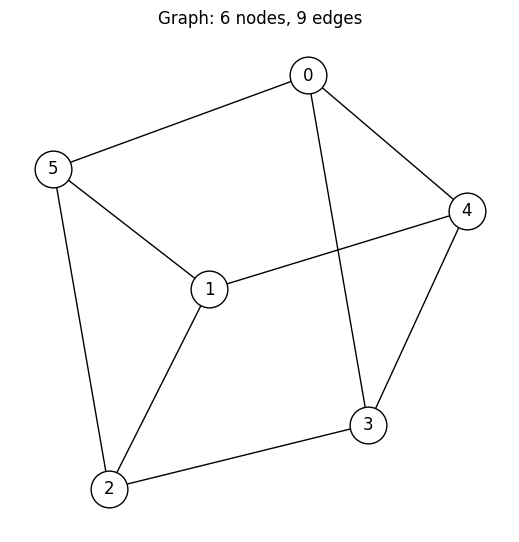

In [4]:
num_nodes = 6
# Triangular prism: the triangles {0, 3, 4} and {1, 2, 5} joined by a perfect
# matching (0-5, 1-4, 2-3). Separating the two triangles cuts only the three
# matching edges; every other equal split breaks a triangle and cuts more, so
# the optimal partition is unique.
edge_list = [
    [0, 3],
    [0, 4],
    [0, 5],
    [1, 2],
    [1, 4],
    [1, 5],
    [2, 3],
    [2, 5],
    [3, 4],
]

G = nx.Graph()
G.add_nodes_from(range(num_nodes))
G.add_edges_from(edge_list)
assert G.number_of_nodes() == num_nodes
assert G.number_of_edges() == len(edge_list)

pos = nx.spring_layout(G, seed=1)
plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_color="white", node_size=700, edgecolors="black")
plt.title(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
plt.show()

In [5]:
instance_data = {"V": num_nodes, "E": edge_list}
instance = problem.eval(instance_data)

## Algorithm

Write the Ising cost Hamiltonian as $H$ and pick a threshold $\mu$. The
algorithm works with the shifted operator $H - \mu I$, whose eigenvalues are
$E_i - \mu$: negative exactly for the eigenstates we want to keep, positive
for the rest. Separating the two sides is therefore the job of the sign
function.

A block encoding embeds a non-unitary operator as one block of a larger
unitary $U$. LCU builds it by writing $H - \mu I$ as a weighted sum of Pauli
strings; the price is a subnormalization $\alpha'$, so the block actually
encoded is the normalized operator $(H - \mu I) / \alpha'$, whose spectrum
lies in $[-1, 1]$. The block is selected by an ancilla register — the *signal*
register — measuring all zero.

QSVT then replaces the encoded operator by a polynomial of it. Given phases
$\Phi$, it applies the alternation

$$R(\phi_0),\; U,\; R(\phi_1),\; U^\dagger,\; \dots$$

and encodes a polynomial response in the same block. Extracting its real
component gives $p\!\left((H - \mu I)/\alpha'\right)$. Choosing
$p$ to approximate the sign function,

$$p\!\left(\frac{H - \mu I}{\alpha'}\right) \approx
\operatorname{sign}\!\left(\frac{H - \mu I}{\alpha'}\right),$$

makes that block a *reflection* $R$: it acts as $-1$ on the eigenspace below
$\mu$ and as $+1$ on the one above.

A reflection is not yet a projector, but $P_\mu = (I - R)/2$ is, and it is a
sum of two unitaries, so a Hadamard test on one extra qubit realises it
probabilistically. The implementation also uses one extra qubit to extract
the real component of the QSVT response; this qubit must also measure zero.
Starting from the uniform superposition
$|\varphi_0\rangle = H^{\otimes n}|0\rangle$, the fraction of shots with every
ancilla measuring zero estimates

$$P(\mu)=\lVert P_\mu |\varphi_0\rangle \rVert^2 \approx \frac{\#\{i : E_i < \mu\}}{2^n},$$

the fraction of the spectrum below $\mu$ in the ideal sign-filter limit.
That single number is the predicate
a classical binary search needs: it is bounded away from zero exactly when an
eigenstate below $\mu$ carries weight in $|\varphi_0\rangle$.

The search itself is Algorithm 1 of Lin and Tong
{cite:p}`10.48550/arXiv.2002.12508`. Eigenvalues live in
$[c-\alpha, c+\alpha)$, where $\alpha$ is the subnormalization of $H$ alone and
$c$ its constant. Compare a threshold $\mu$ to the ground energy $\lambda_0$:
on $[c-\alpha, \lambda_0)$ every eigenvalue is filtered out and $P(\mu)=0$; on
$[\lambda_0, \lambda_1)$ only the ground eigenspace survives, contributing
$\gamma^2 = d/2^n$ for a $d$-fold degeneracy; above $\lambda_1$ the probability
only grows. The search therefore divides $[c-\alpha, c+\alpha)$ into a grid of
spacing $h$ and moves according to whether $P(\mu)$ exceeds
$\tau = \gamma^2/2$.

Two inputs make or break it. $\gamma$ is a lower bound on the initial overlap
and is not known in advance, so it has to be assumed; and $h$ must be smaller
than the (also unknown) spectral gap. Finally, approximation error can make the
estimated $P(\mu)$ non-monotonic, so the search evaluates a *bracket* of two
consecutive grid points $(B_k, B_{k+1})$ rather than trusting a single one.

## Implementation with Qamomile

Qamomile provides the eigenstate-filtering algorithm described above as
`QSVTEigenstateFilterExperiment` in `qamomile.optimization.qsvt_eigenstate_filter`.
`OMMXProblem.from_instance` converts the modeled problem into a binary model,
retaining the default constraint penalties. The experiment builds the block
encoding of the problem Hamiltonian, synthesizes
the filter phases, assembles the probe circuit, and post-selects and decodes the
measured samples, so the whole procedure runs directly from the problem
instance. Below, we first use it to test one threshold, then open up the
building blocks it assembles, and finally drive the binary search with it.

Several internal parameters decide the solution quality, and we explain each of
them below, as well as how to choose them.

The constant term of the Ising Hamiltonian is held out of the block encoding.
The method's performance is tied to the subnormalization $\alpha$, and an
identity term makes it grow, while a constant offset shifts every eigenvalue
equally without changing which state is best. `normalization` ($\alpha$) and
`energy_offset` ($c$) together bound the spectrum, and that interval is what a
threshold gets chosen against.

In [6]:
optimization_problem = OMMXProblem.from_instance(instance)
model = optimization_problem.model
spin = model.to_ising()
energy_offset = float(spin.constant)
normalization = sum(abs(coeff) for coeff in spin.coefficients.values())
# One seeded backend for every circuit on this page, so the printed numbers are
# reproducible from one run to the next.
backend = Aer(seed_transpiler=SEED)

low = energy_offset - normalization
high = energy_offset + normalization
print(f"alpha={normalization}  offset={energy_offset}")
print(f"every eigenvalue lies in [{low}, {high}]")

# Reference spectrum: the Ising operator is diagonal, so we can read the exact
# energies off directly and check the search against them later.
# !!! This is only a check and the computation takes exponential time in general.
energies = np.full(1 << spin.num_variables, float(spin.constant))
for state in range(energies.size):
    for word, coeff in spin.coefficients.items():
        parity = sum((state >> i) & 1 for i in word) & 1
        energies[state] += coeff * (-1.0 if parity else 1.0)

ground_energy = float(energies.min())
degeneracy = int((energies == ground_energy).sum())
print(f"levels={np.unique(energies)}  ground={ground_energy} ({degeneracy}-fold)")

assert low <= energies.min() and energies.max() <= high

alpha=3.0  offset=6.0
every eigenvalue lies in [3.0, 9.0]
levels=[3. 5. 7. 9.]  ground=3.0 (2-fold)


### One threshold

The experiment bakes $\mu$ into the circuit, so each threshold needs its own
compilation. The filter keeps the eigenspace below $\mu$ by default, which is
what a search for the minimum eigenvalue (ground energy) wants.

`degree` and `delta` are paired: `delta` sets the width of the polynomial's
transition and `degree` is the degree of the Chebyshev expansion, which must be
large enough to represent it.

:::{note}
If not chosen, `degree` and `delta` are set to a default value by the
experiment.
:::

The resolution is given by

$$
\Delta = \frac{\min_i |E_i-\mu|}{\alpha + |\mu - c|}
$$

where $E_i$ are the eigenvalues and the other parameters were defined
previously. As often, knowing the resolution requires knowing the ground energy
in advance; in practice we need to guess or estimate a bound to ensure beating
the resolution. The `degree` roughly scales as $O(1/\Delta)$.

Below we demonstrate the algorithm for $\mu=4$. The resolution to beat is then
$\Delta = \frac{|4-3|}{3 + |4 - 6|} = 1/5$, a choice of `delta=8` matches the
transition to the gap and `degree=21` represents it. A bad pairing is not a
silent loss of accuracy: it is rejected outright by the $|p| \le 1$ check.

We use 8,000 shots per probe because the search also visits $\mu=3.5$, where
the finite polynomial gives a success probability of about $0.02198$, close
to the predicate threshold $\tau=0.015625$. With only 2,000 shots, sampling
fluctuations can cross that threshold even when the circuit implements the
intended polynomial correctly. Increasing the shot count reduces that risk
without changing the polynomial or the paired-probe search below.

:::{note}
Documentation tests use degree-one certified polynomials and one shot per
execution to check the filter, search, and decoding paths. They allow an empty
post-selected sample set. Accuracy and ground-state checks use the normal
reader-facing settings described here.
:::

In [7]:
DEGREE, DELTA = (1, 1) if docs_test_mode else (21, 8)
SHOTS = 1 if docs_test_mode else 8000
probe_polynomial = synthesize_sign_filter(degree=DEGREE, delta=DELTA)
print(
    f"probe filter: degree={DEGREE}, delta={DELTA} -> {len(probe_polynomial.phases.phases)} phases"
)


def probe(mu, shots=SHOTS):
    """Estimate the fraction of the spectrum below `mu`."""
    experiment = QSVTEigenstateFilterExperiment(
        model, mu=mu, polynomial=probe_polynomial
    )
    return experiment.run(on=backend, shots=shots, seed=SEED).success_probability


# Two of the 64 states sit at the ground energy, so the predicate saturates at
# 2 / 64 once mu clears it.
sampled_p4 = probe(4.0)
exact_p4 = float((energies < 4.0).mean())
print(f"p(mu=4.0) = {sampled_p4:.4f}   (exact: {exact_p4:.4f})")

# Six standard deviations of shot noise, plus a small allowance for the blur of
# a finite-degree sign approximation.
shot_noise = 6.0 * np.sqrt(exact_p4 * (1.0 - exact_p4) / SHOTS)
assert 0.0 <= sampled_p4 <= 1.0
if not docs_test_mode:
    assert abs(sampled_p4 - exact_p4) < shot_noise + 0.01

probe filter: degree=21, delta=8 -> 22 phases


p(mu=4.0) = 0.0310   (exact: 0.0312)


An external library, `pyqsp`, computes the phase factors corresponding to the
polynomial approximation defined by our parameters. `synthesize_sign_filter`
asks Rust to independently verify the real polynomial and its phase response
before accepting the candidate.

The experiment builds the quantum circuit of the projector. The circuit is run
and we compute the success probability from the sample counts with the
returned `success_probability` value. (The exact computation above is only a reference
used to check the precision.)

### Building blocks

The experiment composes three circuits, each wrapping the previous one.

#### 1. The block encoding $U$

The Ising Hamiltonian is written as a linear combination of unitaries and
realised as $\operatorname{PREPARE}$, $\operatorname{SELECT}$,
$\operatorname{PREPARE}^\dagger$. $\operatorname{PREPARE}$ loads the
coefficient amplitudes onto the signal register, $\operatorname{SELECT}$
applies the corresponding Pauli-$Z$ term to the system conditioned on the
signal, and $\operatorname{PREPARE}^\dagger$ un-computes.

The result is a unitary whose top-left block, the part selected by the signal
register measuring all zero, is $(H - \mu I)/\alpha'$. Nothing outside that
block is useful, which is why every shot must be post-selected on it.

#### 2. The QSVT alternation

Given the block encoding, `qsvt` applies

$$R(\phi_0),\; U,\; R(\phi_1),\; U^\dagger,\; R(\phi_2),\; U,\; \dots$$

with $U$ the block encoding built above and $R(\phi) = e^{i\phi(2\Pi - I)}$,
where $\Pi$ projects the signal register onto all zero. The primitive owns the
whole sequence: it alternates $U$ with $U^\dagger$ and applies the phases.

The effect is to replace the encoded operator by a polynomial of it. With the
phases `pyqsp` produced, the real component approximates $\mathrm{sign}$.
Extracting that real component therefore gives an approximate reflection
about the eigenspace on one side of $\mu$.

#### 3. The Lin & Tong projector

The goal is to turn the reflection into the projection $P_\mu = (I - R)/2$.
However, this projector is **not unitary**, so no circuit can simply apply it.

The trick is that it is a sum of two unitaries, $I$ and $R$, so a Hadamard test
can realise it probabilistically. The test uses one extra ancilla, the *probe
qubit*, which coherently selects between the identity and reflection branches:
it is put in superposition, the QSVT reflection is applied under its control,
and a second Hadamard interferes the two branches. Measuring the probe qubit as
zero heralds the branch where $P_\mu$ was applied; that is why the algorithm has
a success probability at all, and why the post-selection is on the probe **and**
the signal register together. The real-component extraction adds another
success qubit before this step, so the implementation post-selects on both
extra qubits and the original signal register.

### The binary search

The predicate is now everything the classical search needs. `B(k)` is the
single bit "the grid point $x_k$ sees the retained eigenspace", and the loop
consumes those bits in consecutive pairs, as described in the Algorithm
section.

In [8]:
def binary_search_ground_energy(success_prob, low, high, gamma, h=1.0):
    """Algorithm 1 of Lin & Tong: paired (B_k, B_k+1) probes.

    Grid x_k = low + (k + 0.5) * h: the half-cell offset keeps thresholds
    between candidate energies, since the strict comparison in the predicate
    would read zero on a threshold sitting exactly on an eigenvalue. B_k = 1
    iff the estimated probability exceeds tau = gamma**2 / 2.

    The paired-probe loop narrows to at most four cells; a linear scan over
    those finishes the job, so the returned bracket is one cell wide.
    Returns (x_L, x_U) with x_L <= lambda_0 <= x_U -- closed on the left so a
    ground energy sitting exactly on `low` is still bracketed.
    """
    n_grid = int(round((high - low) / h))
    grid = [low + (k + 0.5) * h for k in range(n_grid)]
    tau = 0.5 * gamma**2
    cache = {}

    def B(k):
        # Boundary sentinels: B_-1 = 0 (nothing below), B_G = 1 (all below).
        if not 0 <= k < n_grid:
            return 0 if k < 0 else 1
        if k not in cache:
            cache[k] = success_prob(grid[k])
        return int(cache[k] > tau)

    L, U = 0, n_grid - 1
    print(f"grid {grid[0]:+.2f}..{grid[-1]:+.2f}  G={n_grid}  h={h}  tau={tau:.4f}")

    while U - L > 3:
        k = (L + U) // 2
        bk, bk1 = B(k), B(k + 1)
        print(
            f"  k={k}: B({grid[k]:+.2f})={bk}  B({grid[k + 1]:+.2f})={bk1}",
            end="  ->  ",
        )
        if bk == 1 and bk1 == 1:  # lambda_0 < x_k+1
            U = k + 1
            print(f"(1,1) U<-{U}  [{grid[L]:+.2f}, {grid[U]:+.2f}]")
        elif bk == 0 and bk1 == 0:  # lambda_0 > x_k
            L = k
            print(f"(0,0) L<-{L}  [{grid[L]:+.2f}, {grid[U]:+.2f}]")
        elif bk == 0 and bk1 == 1:  # x_k-1 < lambda_0 < x_k+2
            L, U = max(k - 1, 0), min(k + 2, n_grid - 1)
            print(f"(0,1) -> [{grid[L]:+.2f}, {grid[U]:+.2f}]")
            break
        else:  # x_k < lambda_0 < x_k+1
            L, U = k, k + 1
            print(f"(1,0) -> [{grid[L]:+.2f}, {grid[U]:+.2f}]")
            break

    # Tighten to a single cell: the first grid point whose predicate fires is
    # the smallest threshold that still sees the ground eigenspace. Clamping to
    # the spectrum bound keeps the bracket physical -- no probe is needed below
    # `low`, because no eigenvalue can be there.
    for k in range(L, U + 1):
        if B(k):
            print(f"  refine: first B=1 at k={k} ({grid[k]:+.2f})")
            return max(grid[k] - h, low), grid[k]
    return grid[U], min(grid[U] + h, high)

## Result

Running the search brackets the ground energy without ever being told where it
is. Feeding the resulting threshold back into the filter then prepares the
ground state itself, and sampling it recovers the partition.

In [9]:
gamma = np.sqrt(degeneracy / energies.size)
x_lower, x_upper = binary_search_ground_energy(probe, low, high, gamma=gamma, h=1.0)

print(
    f"\nlambda_0 in [{x_lower:+.2f}, {x_upper:+.2f}]   true lambda_0 = {ground_energy:+.2f}"
)
assert low <= x_lower <= x_upper <= high
if not docs_test_mode:
    assert x_lower <= ground_energy <= x_upper

grid +3.50..+8.50  G=6  h=1.0  tau=0.0156


  k=2: B(+5.50)=1  B(+6.50)=1  ->  (1,1) U<-3  [+3.50, +6.50]


  refine: first B=1 at k=0 (+3.50)

lambda_0 in [+3.00, +3.50]   true lambda_0 = +3.00


:::{note}
Deciding whether $P(\mu)>\tau$ in the binary search tolerates a blurry filter,
and that is why `degree=21` was enough for every probe. To keep *only* the
ground eigenspace, at $\mu = 3.5$ the optimal resolution is $\Delta = 0.09$
rather than the $0.20$ used by the search, so the final decode exploits a
sharper polynomial. Raising `degree` alone does not guarantee a sharper
transition: `degree` and `delta` must be chosen together so the polynomial
stays bounded and resolves the gap. The observed ground-state fraction also
depends on the polynomial response and the sampled shots, so we check it
explicitly below.
:::

In [10]:
# The reader-facing predicate uses degree 21; extracting the state itself
# needs a sharper filter at the same threshold.
DECODE_DEGREE, DECODE_DELTA = (1, 1) if docs_test_mode else (41, 11)
FINAL_SHOTS = 1 if docs_test_mode else 20000
decode_polynomial = synthesize_sign_filter(degree=DECODE_DEGREE, delta=DECODE_DELTA)
print(
    f"decode filter: degree={DECODE_DEGREE}, delta={DECODE_DELTA} -> {len(decode_polynomial.phases.phases)} phases"
)

decode_experiment = QSVTEigenstateFilterExperiment(
    model, mu=x_upper, polynomial=decode_polynomial
)
run = decode_experiment.run(on=backend, shots=FINAL_SHOTS, seed=SEED)
result = run.execution.result
sampleset = run.samples
assert result.shots == FINAL_SHOTS
assert sum(result.counts.values()) == FINAL_SHOTS
best = None
if sampleset is None:
    assert docs_test_mode
    print("No accepted samples in the smoke run")
else:
    kept = sampleset.total_occurrences
    optimal = sum(
        sample.occurrences
        for sample in sampleset.samples
        if np.isclose(sample.energy, ground_energy)
    )
    print(
        f"kept {kept} of {result.shots} shots, {optimal / kept:.1%} at the ground energy"
    )

    best = max(sampleset.samples, key=lambda sample: sample.occurrences).values
    side = sorted(v for v, bit in best.items() if bit == 1)
    cut = sum(1 for u, v in edge_list if best[u] != best[v])
    print(f"most sampled partition: {side} | cut={cut}")

    assert all(
        sample.energy == model.energy(sample.values) for sample in sampleset.samples
    )
    if not docs_test_mode:
        assert optimal / kept > 0.85
        assert cut == 3 and len(side) == num_nodes // 2

decode filter: degree=41, delta=11 -> 42 phases


kept 510 of 20000 shots, 100.0% at the ground energy
most sampled partition: [0, 3, 4] | cut=3


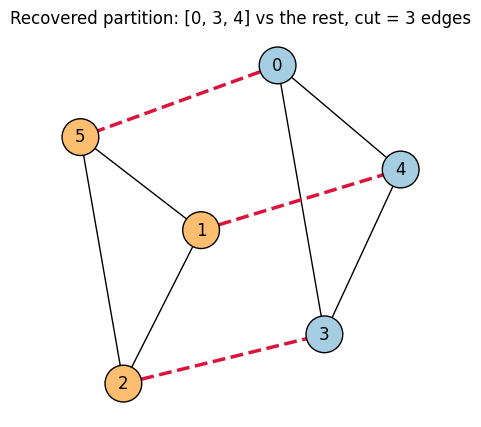

In [11]:
# Draw the recovered partition on the same layout as the input graph: node
# colour is the side, and the cut edges are the objective being minimised.
if best is not None:
    cut_edges = [(u, v) for u, v in G.edges() if best[u] != best[v]]
    kept_edges = [(u, v) for u, v in G.edges() if best[u] == best[v]]

    plt.figure(figsize=(5, 5))
    nx.draw_networkx_edges(G, pos, edgelist=kept_edges, edge_color="black", width=1.0)
    nx.draw_networkx_edges(
        G, pos, edgelist=cut_edges, edge_color="crimson", width=2.5, style="dashed"
    )
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=["#a6cee3" if best[v] == 1 else "#fdbf6f" for v in G.nodes()],
        node_size=700,
        edgecolors="black",
    )
    nx.draw_networkx_labels(G, pos)
    plt.title(f"Recovered partition: {side} vs the rest, cut = {cut} edges")
    plt.axis("off")
    plt.show()

The two triangles $\{0,3,4\}$ and $\{1,2,5\}$ describe the same split, so
either side may come out on top from one run to the next; the corresponding
objective (minimal cut) is $3$.

## Summary

In this notebook, we:

- Solved a graph-partitioning instance end to end with
  `QSVTEigenstateFilterExperiment`, recovering the unique optimal split of the
  triangular prism.
- Saw why the algorithm is probabilistic: $P_\mu = (I - R)/2$ is not unitary,
  so a Hadamard test realises it and every shot must be post-selected on the
  probe, real-component extraction, and signal registers together.
- Saw that every knob traces back to one number, the normalized gap
  $\Delta = \min_i |E_i - \mu| / \alpha'$, which is also why holding the Ising
  constant out of the block encoding matters and why `normalization` and
  `energy_offset` are reported as a pair.